# Ontology Generation for MC-ECII (OWL + Description Logic)

Converts the processed survey data into a **reasoner-usable knowledge base**:

1. Build an OWL ontology (`Student` class, data properties, risk classes).
2. Define **binary predicate concepts** (HighStudyHours, LowSleep, HighAnxiety, ...) as **Description-Logic equivalent classes** with datatype restrictions.
3. Create one `Student` individual per record (3 data-property assertions per feature).
4. Run a **DL reasoner (HermiT)** to infer which predicate concepts each student satisfies.
5. Export: `student_stress.owl`, `predicate_matrix.csv`, thresholds, and a starter class-wise coverage Cov(c,k) table for MC-ECII.

Thresholds are computed from the **training split only** (random_state = 42, same split as the ML notebook) and are documented modelling decisions, **not clinical cut-offs**.

Upload `Processed_Student_Stress_Data.csv` when asked.

## 1. Setup

In [1]:
!pip -q install owlready2

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.4/27.4 MB 60.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, time, shutil, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from owlready2 import *

os.makedirs('outputs', exist_ok=True)
RANDOM_STATE = 42; CLASS_ORDER = ['Low', 'Medium', 'High']
CSV_NAME = 'Processed_Student_Stress_Data.csv'
try:
    from google.colab import files
    if not os.path.exists(CSV_NAME):
        up = files.upload(); CSV_NAME = list(up.keys())[0]
except ImportError:
    pass
df = pd.read_csv(CSV_NAME)
print(df.shape)

# Java is needed by the HermiT reasoner (pre-installed on Colab)
JAVA_OK = shutil.which('java') is not None
print('Java available:', JAVA_OK)

(2066, 33)
Java available: True


## 2. Train/test split and predicate thresholds (training data only)

In [4]:
train_idx, test_idx = train_test_split(df.index, test_size=0.20, stratify=df['Stress_Level'], random_state=RANDOM_STATE)
df['Split'] = 'train'; df.loc[test_idx, 'Split'] = 'test'
train_df = df.loc[train_idx]
print(df['Split'].value_counts().to_dict())

{'train': 1652, 'test': 414}


In [5]:
# ---- Predicate definitions (identical in the ontology notebook) ----
# Numeric thresholds come from TRAINING data quantiles (documented modelling choices, NOT clinical cut-offs).
def build_predicates(train_df):
    q = lambda col, p: round(float(train_df[col].quantile(p)), 1)
    return [
        # name,                 column,               op,   value
        ('HighStudyHours',      'Study_Hours',        '>=', q('Study_Hours', .75)),
        ('LowSleep',            'Sleep_Hours',        '<=', q('Sleep_Hours', .25)),
        ('LowAttendance',       'Class_Attendance',   '<=', q('Class_Attendance', .25)),
        ('HighSocialMedia',     'Social_Media_Use',   '>=', q('Social_Media_Use', .75)),
        ('HighScreenTime',      'Screen_Time',        '>=', q('Screen_Time', .75)),
        ('HighAnxiety',         'Anxiety_Level',      '>=', q('Anxiety_Level', .75)),
        ('HighExamFrequency',   'Exam_Frequency',     '==', 'High'),
        ('HighAssignmentLoad',  'Assignment_Load',    '==', 'High'),
        ('LowExercise',         'Physical_Exercise',  '==', 'Low'),
        ('HighPeerPressure',    'Peer_Pressure',      '==', 'High'),
        ('LowFamilySupport',    'Family_Support',     '==', 'Low'),
        ('HighTuitionBurden',   'Tuition',            '==', 'High'),
        ('LowIncome',           'Family_Income_Level', '==', 'Low'),
        ('PrivateUniversity',   'University_Type',    '==', 'Private'),
    ]

def eval_predicate(value, op, thr):
    return (value >= thr) if op == '>=' else (value <= thr) if op == '<=' else (value == thr)

def predicate_matrix(df_, preds):
    out = pd.DataFrame(index=df_.index)
    for name, col, op, thr in preds:
        out[name] = eval_predicate(df_[col], op, thr).astype(int)
    return out


In [6]:
predicates = build_predicates(train_df)
thr_table = pd.DataFrame(predicates, columns=['Predicate', 'Source column', 'Operator', 'Threshold / value'])
thr_table.to_csv('outputs/predicate_thresholds.csv', index=False)
thr_table

,Predicate,Source column,Operator,Threshold / value
0,HighStudyHours,Study_Hours,>=,8.0
1,LowSleep,Sleep_Hours,<=,6.0
2,LowAttendance,Class_Attendance,<=,70.0
3,HighSocialMedia,Social_Media_Use,>=,5.0
4,HighScreenTime,Screen_Time,>=,7.0
5,HighAnxiety,Anxiety_Level,>=,7.0
6,HighExamFrequency,Exam_Frequency,==,High
7,HighAssignmentLoad,Assignment_Load,==,High
8,LowExercise,Physical_Exercise,==,Low
9,HighPeerPressure,Peer_Pressure,==,High


## 3. Build the ontology (classes, properties, DL definitions, individuals)

In [7]:
import types
ONTO_IRI = 'http://example.org/student-stress.owl'

# column -> (data property name, python type)
PROPS = {
 'Age': ('hasAge', int), 'Study_Hours': ('hasStudyHours', float), 'Class_Attendance': ('hasAttendance', float),
 'Sleep_Hours': ('hasSleepHours', float), 'Social_Media_Use': ('hasSocialMediaHours', float),
 'Screen_Time': ('hasScreenTimeHours', float), 'Anxiety_Level': ('hasAnxietyLevel', float),
 'Gender': ('hasGender', str), 'State': ('hasState', str), 'Exam_Frequency': ('hasExamFrequency', str),
 'Assignment_Load': ('hasAssignmentLoad', str), 'Physical_Exercise': ('hasExerciseLevel', str),
 'Peer_Pressure': ('hasPeerPressure', str), 'Family_Support': ('hasFamilySupport', str),
 'Family_Income_Level': ('hasIncomeLevel', str), 'Tuition': ('hasTuitionBurden', str),
 'University_Type': ('hasUniversityType', str), 'Split': ('hasSplit', str),
}

def build_ontology(data, predicates, iri=ONTO_IRI):
    """Builds the schema (classes, properties, DL definitions) and one individual per row of `data`.
    Uses its own World so several ontologies can exist side by side."""
    world = World(); onto = world.get_ontology(iri)
    with onto:
        class Student(Thing): pass
        class RiskClass(Student): pass
        class LowRiskStudent(RiskClass): pass
        class MediumRiskStudent(RiskClass): pass
        class HighRiskStudent(RiskClass): pass
        AllDisjoint([LowRiskStudent, MediumRiskStudent, HighRiskStudent])

        dprops = {}
        for col, (pname, ptype) in PROPS.items():
            dprops[col] = types.new_class(pname, (DataProperty, FunctionalProperty),
                                          exec_body=lambda ns, t=ptype: ns.update(domain=[Student], range=[t]))
        pred_classes, dl_text = {}, []
        for name, col, op, thr in predicates:                       # predicate concepts as DL equivalent classes
            C = types.new_class(name, (Student,)); pred_classes[name] = C
            pname, ptype = PROPS[col]
            if ptype is str:
                C.equivalent_to = [Student & dprops[col].value(thr)]
                dl_text.append(f'{name} ≡ Student ⊓ ∃{pname}.{{"{thr}"}}')
            else:
                cd = (ConstrainedDatatype(ptype, min_inclusive=ptype(thr)) if op == '>='
                      else ConstrainedDatatype(ptype, max_inclusive=ptype(thr)))
                C.equivalent_to = [Student & dprops[col].some(cd)]
                dl_text.append(f'{name} ≡ Student ⊓ ∃{pname}.[{"≥" if op == ">=" else "≤"} {thr}]')
        risk_cls = {'Low': LowRiskStudent, 'Medium': MediumRiskStudent, 'High': HighRiskStudent}
        for _, r in data.iterrows():                                  # one individual per record
            st = Student(r['Student_ID'])
            for col, (pname, ptype) in PROPS.items():
                setattr(st, pname, ptype(r[col]))
            st.is_a.append(risk_cls[r['Stress_Level']])               # asserted target class (for concept induction)
    return world, onto, Student, pred_classes, dl_text

# FULL ontology with all students -> saved as OWL (open it in Protege)
world, onto, Student, pred_classes, dl_text = build_ontology(df, predicates)
onto.save(file='outputs/student_stress.owl', format='rdfxml')
print('\n'.join(dl_text))
print('\nIndividuals in full ontology:', len(list(Student.instances())))

HighStudyHours ≡ Student ⊓ ∃hasStudyHours.[≥ 8.0]
LowSleep ≡ Student ⊓ ∃hasSleepHours.[≤ 6.0]
LowAttendance ≡ Student ⊓ ∃hasAttendance.[≤ 70.0]
HighSocialMedia ≡ Student ⊓ ∃hasSocialMediaHours.[≥ 5.0]
HighScreenTime ≡ Student ⊓ ∃hasScreenTimeHours.[≥ 7.0]
HighAnxiety ≡ Student ⊓ ∃hasAnxietyLevel.[≥ 7.0]
HighExamFrequency ≡ Student ⊓ ∃hasExamFrequency.{"High"}
HighAssignmentLoad ≡ Student ⊓ ∃hasAssignmentLoad.{"High"}
LowExercise ≡ Student ⊓ ∃hasExerciseLevel.{"Low"}
HighPeerPressure ≡ Student ⊓ ∃hasPeerPressure.{"High"}
LowFamilySupport ≡ Student ⊓ ∃hasFamilySupport.{"Low"}
HighTuitionBurden ≡ Student ⊓ ∃hasTuitionBurden.{"High"}
LowIncome ≡ Student ⊓ ∃hasIncomeLevel.{"Low"}
PrivateUniversity ≡ Student ⊓ ∃hasUniversityType.{"Private"}

Individuals in full ontology: 2066


## 4. Run the DL reasoner (HermiT) – validation on a sample
HermiT's run-time grows quickly with the number of individuals (about 10 s for 150 students, about 50 s for 400, much longer for 2,000+).
So the reasoner is run on a **stratified sample** (`REASONER_N`, default 300). The inferred memberships are compared with the direct threshold
computation; if they are identical on the sample, the full predicate matrix can be generated directly. Set `REASON_ALL = True` to reason over all students (slow, possibly 20-30+ minutes).

In [8]:
REASON_ALL = False
REASONER_N = 300
inferred, sample_ids = None, None
if JAVA_OK:
    n_per = min(REASONER_N // 3, int(df['Stress_Level'].value_counts().min()))
    sample = df if REASON_ALL else df.groupby('Stress_Level').sample(n=n_per, random_state=RANDOM_STATE)
    sample_ids = sample['Student_ID'].tolist()
    w2, onto2, Student2, pred2, _ = build_ontology(sample, predicates, iri='http://example.org/student-stress-sample.owl')
    t0 = time.time()
    try:
        with onto2:
            sync_reasoner_hermit(w2, infer_property_values=False)
        inferred = pd.DataFrame(0, index=sample_ids, columns=[p[0] for p in predicates])
        for st in Student2.instances():
            for c in st.is_a:
                if getattr(c, 'name', None) in pred2: inferred.loc[st.name, c.name] = 1
        print(f'Reasoner finished on {len(sample_ids)} students in {time.time()-t0:.1f}s')
    except Exception as e:
        print('Reasoner failed -> direct computation only. Reason:', repr(e)[:300])
else:
    print('Java not found -> reasoner skipped (direct computation only).')
inferred.sum().sort_values(ascending=False) if inferred is not None else 'Reasoner not run'

* Owlready2 * Running HermiT...
    java -Xmx2000M -cp /usr/local/lib/python3.13/dist-packages/owlready2/hermit:/usr/local/lib/python3.13/dist-packages/owlready2/hermit/HermiT.jar org.semanticweb.HermiT.cli.CommandLine -c -O -D -I file:////tmp/tmp2lql3v08
* Owlready2 * HermiT took 46.041149616241455 seconds
* Owlready * Reparenting student-stress-sample.S1306: {student-stress-sample.Student, student-stress-sample.LowRiskStudent} => {student-stress-sample.PrivateUniversity, student-stress-sample.LowExercise, student-stress-sample.HighStudyHours, student-stress-sample.LowRiskStudent, student-stress-sample.HighAnxiety, student-stress-sample.LowIncome, student-stress-sample.LowSleep}
* Owlready * Reparenting student-stress-sample.S1426: {student-stress-sample.HighRiskStudent, student-stress-sample.Student} => {student-stress-sample.HighRiskStudent, student-stress-sample.HighStudyHours}
* Owlready * Reparenting student-stress-sample.S1788: {student-stress-sample.MediumRiskStudent, student-s

Reasoner finished on 300 students in 46.4s


* Owlready * Reparenting student-stress-sample.S0434: {student-stress-sample.HighRiskStudent, student-stress-sample.Student} => {student-stress-sample.HighScreenTime, student-stress-sample.HighRiskStudent, student-stress-sample.HighPeerPressure, student-stress-sample.HighAssignmentLoad, student-stress-sample.LowFamilySupport}
* Owlready * Reparenting student-stress-sample.S0313: {student-stress-sample.Student, student-stress-sample.LowRiskStudent} => {student-stress-sample.HighScreenTime, student-stress-sample.LowExercise, student-stress-sample.HighSocialMedia, student-stress-sample.LowRiskStudent, student-stress-sample.LowAttendance}
* Owlready * Reparenting student-stress-sample.S1644: {student-stress-sample.MediumRiskStudent, student-stress-sample.Student} => {student-stress-sample.MediumRiskStudent, student-stress-sample.PrivateUniversity, student-stress-sample.HighTuitionBurden, student-stress-sample.LowExercise, student-stress-sample.HighSocialMedia, student-stress-sample.HighPee

,0
PrivateUniversity,148
LowSleep,128
LowExercise,117
HighScreenTime,104
HighAssignmentLoad,97
HighStudyHours,93
LowAttendance,85
HighPeerPressure,84
HighAnxiety,83
HighSocialMedia,82


## 5. Predicate matrix (all students)

In [9]:
direct = predicate_matrix(df, predicates); direct.index = df['Student_ID']
if inferred is not None:
    same = bool((inferred[direct.columns].values == direct.loc[inferred.index].values).all())
    print(f'Reasoner output identical to the direct threshold computation on {len(inferred)} students:', same)
    assert same, 'Mismatch between reasoner and direct computation - check thresholds / datatypes'


Reasoner output identical to the direct threshold computation on 300 students: True


## 6. Save the predicate matrix (input to ECII / MC-ECII)

In [10]:
pm = direct.copy(); pm['Stress_Level'] = df.set_index('Student_ID')['Stress_Level']; pm['Split'] = df.set_index('Student_ID')['Split']
pm.to_csv('outputs/predicate_matrix.csv')
pm[pm.Split == 'train'].drop(columns='Split').to_csv('outputs/predicate_matrix_train.csv')
pm[pm.Split == 'test'].drop(columns='Split').to_csv('outputs/predicate_matrix_test.csv')
pm.head()

,HighStudyHours,LowSleep,LowAttendance,HighSocialMedia,HighScreenTime,HighAnxiety,HighExamFrequency,HighAssignmentLoad,LowExercise,HighPeerPressure,LowFamilySupport,HighTuitionBurden,LowIncome,PrivateUniversity,Stress_Level,Split
Student_ID,,,,,,,,,,,,,,,,
S0001,0,0,1,0,0,0,1,1,1,0,0,1,1,1,High,train
S0002,0,1,0,0,0,1,0,1,0,0,0,1,1,1,High,test
S0003,0,1,0,0,0,0,1,1,0,0,0,0,0,1,High,train
S0004,0,1,0,0,0,0,1,0,1,0,1,0,0,1,Medium,train
S0005,0,1,1,0,0,1,0,0,1,1,0,0,0,0,Low,test


## 7. Starter for MC-ECII: class-wise coverage Cov(c, k) and coverage vector V(c)

,Cov(Low),Cov(Medium),Cov(High),Norm(Low),Norm(Medium),Norm(High),Class(c),Margin
Concept,,,,,,,,
HighAssignmentLoad,58,162,239,0.104,0.267,0.491,High,0.223
HighExamFrequency,71,155,215,0.127,0.256,0.441,High,0.186
HighPeerPressure,98,144,178,0.175,0.238,0.366,High,0.128
LowFamilySupport,59,118,146,0.106,0.195,0.300,High,0.105
LowSleep,199,247,245,0.356,0.408,0.503,High,0.095
HighAnxiety,109,179,186,0.195,0.295,0.382,High,0.087
HighTuitionBurden,98,148,152,0.175,0.244,0.312,High,0.068
HighScreenTime,184,205,182,0.329,0.338,0.374,High,0.035
HighStudyHours,120,190,165,0.215,0.314,0.339,High,0.025


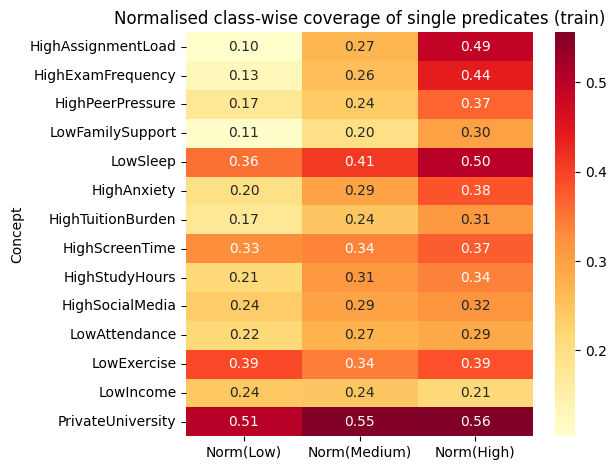

In [11]:
train = pm[pm.Split == 'train']; pred_names = [p[0] for p in predicates]
class_n = train['Stress_Level'].value_counts()
rows = []
for p in pred_names:
    cov = {k: int(((train[p] == 1) & (train['Stress_Level'] == k)).sum()) for k in CLASS_ORDER}
    norm = {k: cov[k] / class_n[k] for k in CLASS_ORDER}            # normalised so the biggest class cannot dominate
    best = max(norm, key=norm.get); srt = sorted(norm.values(), reverse=True)
    rows.append({'Concept': p, **{f'Cov({k})': cov[k] for k in CLASS_ORDER},
                 **{f'Norm({k})': round(norm[k], 3) for k in CLASS_ORDER}, 'Class(c)': best, 'Margin': round(srt[0] - srt[1], 3)})
cov_df = pd.DataFrame(rows).set_index('Concept').sort_values('Margin', ascending=False)
display(cov_df)
sns.heatmap(cov_df[[f'Norm({k})' for k in CLASS_ORDER]], annot=True, fmt='.2f', cmap='YlOrRd')
plt.title('Normalised class-wise coverage of single predicates (train)'); plt.tight_layout()
plt.savefig('outputs/class_wise_coverage.png'); plt.show()
cov_df.to_csv('outputs/class_wise_coverage.csv')

In [12]:
# Candidate concepts of length 2 (conjunctions) – the kind of expressions ECII/MC-ECII would refine and prune
from itertools import combinations
MIN_SUPPORT, rows = 20, []
for a, b in combinations(pred_names, 2):
    m = (train[a] == 1) & (train[b] == 1)
    if m.sum() < MIN_SUPPORT: continue
    norm = {k: ((m) & (train['Stress_Level'] == k)).sum() / class_n[k] for k in CLASS_ORDER}
    best = max(norm, key=norm.get); srt = sorted(norm.values(), reverse=True)
    rows.append({'Concept': f'{a} ⊓ {b}', 'Support': int(m.sum()), 'Class(c)': best,
                 'Precision for class': round(((m) & (train['Stress_Level'] == best)).sum() / m.sum(), 3),
                 'Margin': round(srt[0] - srt[1], 3)})
cand = pd.DataFrame(rows).sort_values(['Class(c)', 'Margin'], ascending=[True, False])
top = cand.groupby('Class(c)').head(5)
top.to_csv('outputs/candidate_concepts_top.csv', index=False); top

,Concept,Support,Class(c),Precision for class,Margin
63,HighExamFrequency ⊓ HighAssignmentLoad,138,High,0.732,0.156
18,LowSleep ⊓ HighAssignmentLoad,207,High,0.560,0.128
56,HighAnxiety ⊓ HighAssignmentLoad,127,High,0.669,0.122
66,HighExamFrequency ⊓ LowFamilySupport,101,High,0.762,0.122
17,LowSleep ⊓ HighExamFrequency,177,High,0.571,0.117
53,HighScreenTime ⊓ LowIncome,136,Low,0.375,0.004
79,LowExercise ⊓ LowIncome,160,Low,0.344,0.001
34,LowAttendance ⊓ LowIncome,99,Medium,0.475,0.024
88,HighTuitionBurden ⊓ LowIncome,98,Medium,0.480,0.018
30,LowAttendance ⊓ LowExercise,168,Medium,0.399,0.014


## 8. Ontology summary and download

In [13]:
print('Classes   :', [c.name for c in onto.classes()])
print('Data props:', [p.name for p in onto.data_properties()])
print('Individuals:', len(list(onto.individuals())))
def tree(c, d=0):
    print('  ' * d + '- ' + c.name)
    for s in c.subclasses(): tree(s, d + 1)
tree(Student)
open('outputs/dl_definitions.txt', 'w', encoding='utf-8').write('\n'.join(dl_text))
shutil.make_archive('ontology_outputs', 'zip', 'outputs')
try:
    from google.colab import files; files.download('ontology_outputs.zip')
except ImportError:
    print('Saved to ./outputs and ontology_outputs.zip')

Classes   : ['Student', 'RiskClass', 'LowRiskStudent', 'MediumRiskStudent', 'HighRiskStudent', 'HighStudyHours', 'LowSleep', 'LowAttendance', 'HighSocialMedia', 'HighScreenTime', 'HighAnxiety', 'HighExamFrequency', 'HighAssignmentLoad', 'LowExercise', 'HighPeerPressure', 'LowFamilySupport', 'HighTuitionBurden', 'LowIncome', 'PrivateUniversity']
Data props: ['hasAge', 'hasStudyHours', 'hasAttendance', 'hasSleepHours', 'hasSocialMediaHours', 'hasScreenTimeHours', 'hasAnxietyLevel', 'hasGender', 'hasState', 'hasExamFrequency', 'hasAssignmentLoad', 'hasExerciseLevel', 'hasPeerPressure', 'hasFamilySupport', 'hasIncomeLevel', 'hasTuitionBurden', 'hasUniversityType', 'hasSplit']
Individuals: 2066
- Student
  - RiskClass
    - LowRiskStudent
    - MediumRiskStudent
    - HighRiskStudent
  - HighStudyHours
  - LowSleep
  - LowAttendance
  - HighSocialMedia
  - HighScreenTime
  - HighAnxiety
  - HighExamFrequency
  - HighAssignmentLoad
  - LowExercise
  - HighPeerPressure
  - LowFamilySupport
  

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>